# skin feature 확장 — eye 수준(전체 RDKit descriptor + Morgan FP)으로 맞춤

**배경**: 기존 skin은 descriptor 8개뿐인데 eye는 8개(공통)+전체 RDKit 217개+Morgan FP 2048개를 쓰고 있었음(이전 세션에서 "skin이 너무 저차원이라 eye를 줄이는 게 낫다"고 제안했으나, **팀 논의 결과 skin을 eye 수준으로 올리는 쪽으로 최종 결정**).

**이 노트북이 하는 일**: 기존 8개 descriptor(MolWt/LogP/TPSA/HBD/HBA/RotatableBonds/AromaticProportion/ESOL_LogS)는 그대로 유지하면서, 다음을 추가합니다.
1. **전체 RDKit descriptor 217개**(`desc_` 접두, `Descriptors._descList` 전체) — 염 제거된 최대 프래그먼트 기준
2. **Morgan fingerprint(ECFP4, radius=2, 2048bit)**(`fp_w_` 접두) — eye와 동일하게 **염 제거 전 원본 분자** 기준(대응이온도 구조정보로 의미가 있고, 비트단위라 분자량처럼 왜곡되지 않는다는 eye팀 설계원칙을 그대로 따름)

최종 feature 차원: 8(기존) + 217(전체 descriptor) + 2048(FP) = **2,273차원** — eye(2,265차원)와 사실상 동급.

> 이 버전은 과정·결과 이해를 돕기 위해 각 단계마다 시각화를 추가하였습니다(파이프라인 개요 / 염 제거 전후 비교 / 결측 현황 / feature 차원·라벨 분포). 2026-10-29: MIX839/840(동일조성·상반라벨) worst-case 통일 반영(둘 다 Category 1로 확정).

In [1]:
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

BASE = r"C:\Users\UserK\학술제\skin irritation"

cache = pd.read_csv(rf"{BASE}\casrn_smiles_cache.csv")
filtered = pd.read_csv(rf"{BASE}\skin_filtered.csv")
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")

resolved = cache[cache["smiles"].notna()].copy()
print(f"구조 확보 성분: {len(resolved)}종")

구조 확보 성분: 264종


## 0단계 — 전체 파이프라인 한눈에 보기

아래 단계들을 실제 수치와 함께 순서대로 보여줍니다.

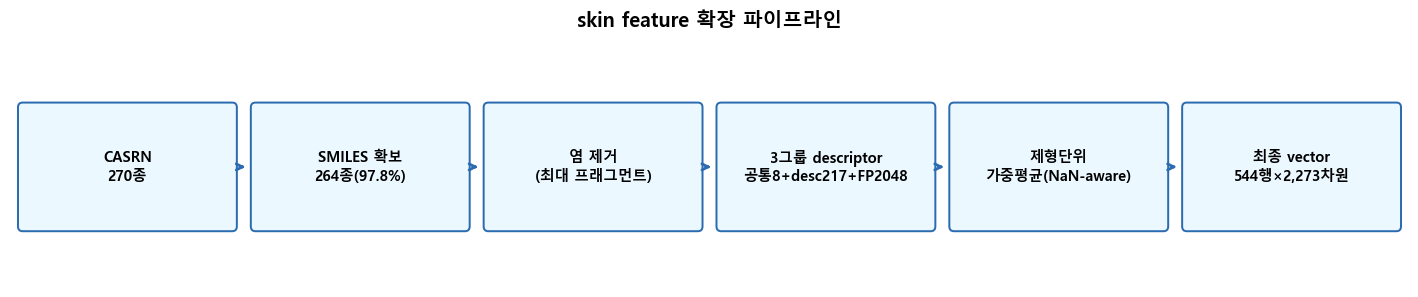

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    "CASRN\n270종",
    f"SMILES 확보\n{len(resolved)}종({len(resolved)/270*100:.1f}%)",
    "염 제거\n(최대 프래그먼트)",
    "3그룹 descriptor\n공통8+desc217+FP2048",
    "제형단위\n가중평균(NaN-aware)",
    "최종 vector\n544행×2,273차원",
]

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.set_xlim(0, len(steps))
ax.set_ylim(0, 1)
ax.axis("off")

for i, text in enumerate(steps):
    box = FancyBboxPatch((i + 0.05, 0.25), 0.9, 0.5, boxstyle="round,pad=0.02",
                          linewidth=1.3, edgecolor="#2b6cb0", facecolor="#ebf8ff")
    ax.add_patch(box)
    ax.text(i + 0.5, 0.5, text, ha="center", va="center", fontsize=9.5, fontweight="bold")
    if i < len(steps) - 1:
        ax.annotate("", xy=(i + 1.02, 0.5), xytext=(i + 0.97, 0.5),
                    arrowprops=dict(arrowstyle="->", lw=1.8, color="#2b6cb0"))

plt.title("skin feature 확장 파이프라인", fontsize=13, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

## 1단계 — 염 제거(최대 프래그먼트) 함수

기존 `skin_feature_rebuild.ipynb`와 완전히 동일한 로직(이미 검증된 방식 재사용).

In [3]:
def get_largest_fragment(mol):
    frags = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    if len(frags) == 1:
        return mol
    return max(frags, key=lambda m: m.GetNumHeavyAtoms())

### 염 제거가 실제로 얼마나 영향을 주는지 시각화

다중 프래그먼트(염·대응이온 포함) 구조만 골라, 염 제거 전/후 분자량을 비교합니다.

다중 프래그먼트(염 포함) 구조: 29종 / 264종


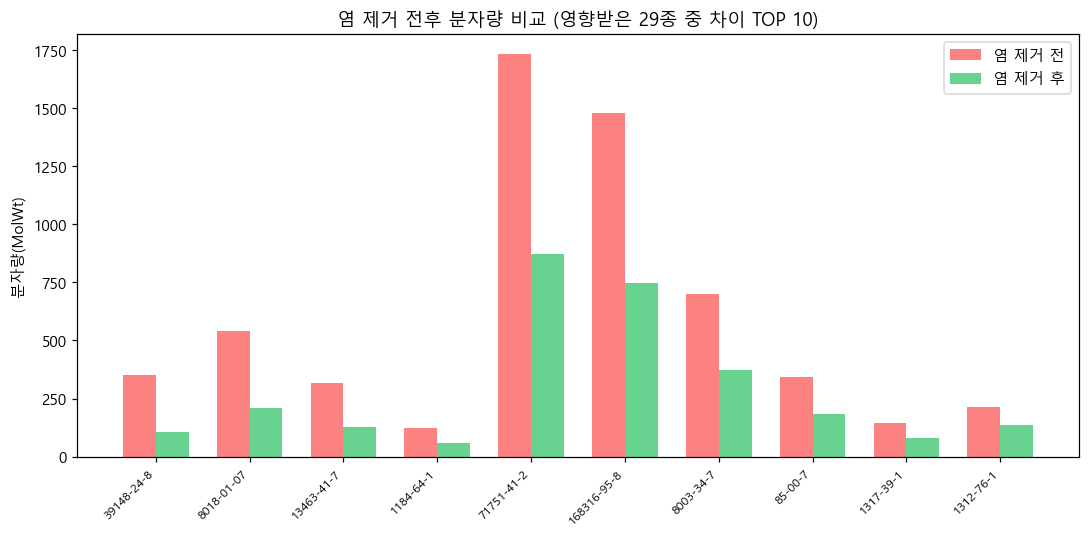

In [4]:
multi_frag = resolved[resolved["smiles"].str.contains(".", regex=False)]
print(f"다중 프래그먼트(염 포함) 구조: {len(multi_frag)}종 / {len(resolved)}종")

before_after = []
for _, r in multi_frag.iterrows():
    mol = Chem.MolFromSmiles(r["smiles"])
    if mol is None:
        continue
    stripped = get_largest_fragment(mol)
    before_after.append({
        "casrn": r["casrn"],
        "MW_before": Descriptors.MolWt(mol), "MW_after": Descriptors.MolWt(stripped),
    })
ba_df = pd.DataFrame(before_after)
ba_df["MW_diff_pct"] = (ba_df["MW_before"] - ba_df["MW_after"]) / ba_df["MW_after"] * 100
top = ba_df.reindex(ba_df["MW_diff_pct"].abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(top))
w = 0.35
ax.bar(x - w/2, top["MW_before"], width=w, label="염 제거 전", color="#fc8181")
ax.bar(x + w/2, top["MW_after"], width=w, label="염 제거 후", color="#68d391")
ax.set_xticks(x)
ax.set_xticklabels(top["casrn"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("분자량(MolWt)")
ax.set_title(f"염 제거 전후 분자량 비교 (영향받은 {len(multi_frag)}종 중 차이 TOP 10)")
ax.legend()
plt.tight_layout()
plt.show()

## 2단계 — descriptor 3그룹 계산

- **8개 공통**: 기존과 동일(염 제거 기준)
- **전체 RDKit 217개**(`desc_`): `Descriptors._descList` 전체, 염 제거 기준. 개별 함수가 실패하거나 `inf`를 반환하면 `NaN` 처리(eye팀이 `Ipc` 등에서 겪은 문제와 동일 — 큰/복잡한 분자에서 수치가 폭주할 수 있음).
- **Morgan FP 2048비트**(`fp_w_`): **염 제거 전 원본 분자** 기준 — 대응이온도 구조정보로서 의미가 있고 비트단위라 왜곡되지 않는다는 eye팀 설계원칙을 그대로 채택.

In [5]:
_FULL_DESC_LIST = Descriptors._descList  # [(name, func), ...] 217개
_MORGAN_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


def compute_common8(mol):
    n_heavy = mol.GetNumHeavyAtoms()
    n_aromatic = sum(1 for a in mol.GetAtoms() if a.GetIsAromatic())
    arom_prop = n_aromatic / n_heavy if n_heavy > 0 else 0.0
    mw = Descriptors.MolWt(mol)
    logp = Crippen.MolLogP(mol)
    rotb = Descriptors.NumRotatableBonds(mol)
    esol_logs = 0.16 - 0.63 * logp - 0.0062 * mw + 0.066 * rotb - 0.74 * arom_prop
    return {
        "MolWt": mw, "LogP": logp, "TPSA": Descriptors.TPSA(mol),
        "HBD": Descriptors.NumHDonors(mol), "HBA": Descriptors.NumHAcceptors(mol),
        "RotatableBonds": rotb, "AromaticProportion": arom_prop, "ESOL_LogS": esol_logs,
    }


def compute_full_descriptors(mol):
    out = {}
    for name, func in _FULL_DESC_LIST:
        try:
            val = func(mol)
            if not np.isfinite(val):
                val = np.nan
        except Exception:
            val = np.nan
        out[f"desc_{name}"] = val
    return out


def compute_morgan_fp(mol):
    fp = _MORGAN_GEN.GetFingerprint(mol)
    arr = np.zeros(2048, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return {f"fp_w_{i}": int(v) for i, v in enumerate(arr)}


rows = []
for _, r in resolved.iterrows():
    mol_orig = Chem.MolFromSmiles(r["smiles"])
    if mol_orig is None:
        continue
    mol_stripped = get_largest_fragment(mol_orig)

    row = {"casrn": r["casrn"]}
    row.update(compute_common8(mol_stripped))
    row.update(compute_full_descriptors(mol_stripped))
    row.update(compute_morgan_fp(mol_orig))  # FP는 원본(염 포함) 기준
    rows.append(row)

desc_full = pd.DataFrame(rows).set_index("casrn")
COMMON8_COLS = ["MolWt", "LogP", "TPSA", "HBD", "HBA", "RotatableBonds", "AromaticProportion", "ESOL_LogS"]
DESC217_COLS = [c for c in desc_full.columns if c.startswith("desc_")]
FP_COLS = [c for c in desc_full.columns if c.startswith("fp_w_")]
print(f"성분 {len(desc_full)}종 x feature {len(COMMON8_COLS)+len(DESC217_COLS)+len(FP_COLS)}개"
      f" (공통8={len(COMMON8_COLS)}, 전체desc={len(DESC217_COLS)}, FP={len(FP_COLS)})")

desc_full.to_csv(rf"{BASE}\casrn_descriptors_full.csv")
print("저장: casrn_descriptors_full.csv")

성분 264종 x feature 2273개 (공통8=8, 전체desc=217, FP=2048)
저장: casrn_descriptors_full.csv


## 3단계 — 결측 현황 점검 (어떤 descriptor가 왜 NaN인지)

In [6]:
nan_counts = desc_full[DESC217_COLS].isna().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)
print(f"NaN이 1건이라도 있는 desc_ 컬럼: {len(nan_counts)}개 / {len(DESC217_COLS)}개")
print(nan_counts.head(15))
print()
print("(무기물·금속 성분에서 Gasteiger 전하 계열(BCUT2D_*, *PartialCharge)이 정의 안 되는 "
      "현상 — eye팀이 보고한 것과 동일한 RDKit 한계. 계산 실패가 아니라 원천적으로 정의되지 않음.)")

NaN이 1건이라도 있는 desc_ 컬럼: 12개 / 217개
desc_MaxPartialCharge       2
desc_MinPartialCharge       2
desc_MaxAbsPartialCharge    2
desc_MinAbsPartialCharge    2
desc_BCUT2D_MWHI            2
desc_BCUT2D_MWLOW           2
desc_BCUT2D_CHGHI           2
desc_BCUT2D_CHGLO           2
desc_BCUT2D_LOGPHI          2
desc_BCUT2D_LOGPLOW         2
desc_BCUT2D_MRHI            2
desc_BCUT2D_MRLOW           2
dtype: int64

(무기물·금속 성분에서 Gasteiger 전하 계열(BCUT2D_*, *PartialCharge)이 정의 안 되는 현상 — eye팀이 보고한 것과 동일한 RDKit 한계. 계산 실패가 아니라 원천적으로 정의되지 않음.)


### 결측(NaN) 상위 15개 descriptor 시각화

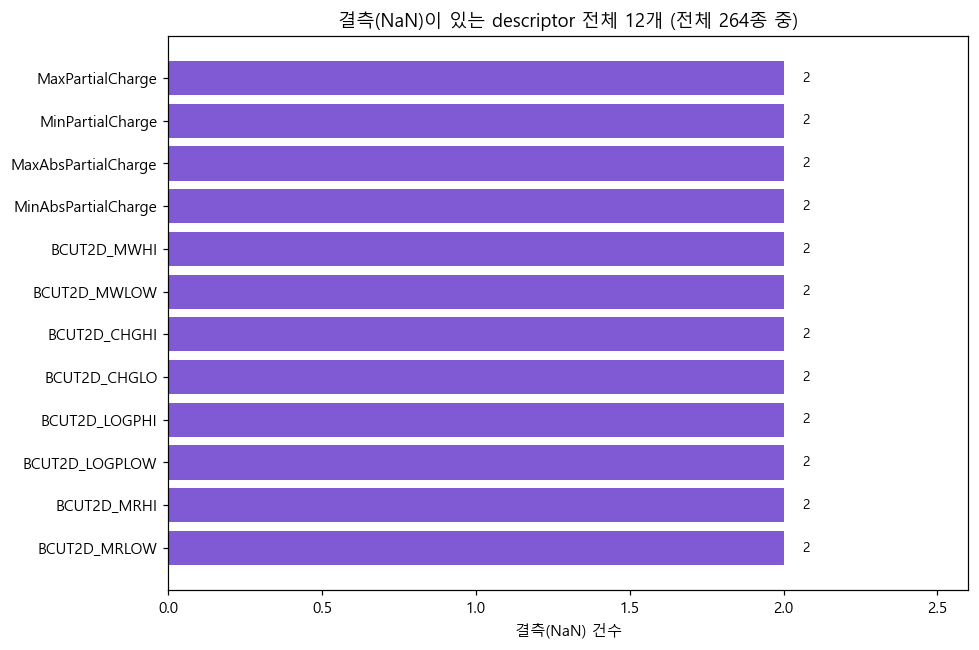

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
top15 = nan_counts.head(15)
ax.barh(top15.index.str.replace("desc_", ""), top15.values, color="#805ad5")
ax.invert_yaxis()
ax.set_xlabel("결측(NaN) 건수")
ax.set_xlim(0, top15.values.max() * 1.3)
ax.set_title(f"결측(NaN)이 있는 descriptor 전체 {len(nan_counts)}개 (전체 {len(desc_full)}종 중)")
for i, v in enumerate(top15.values):
    ax.text(v + top15.values.max() * 0.03, i, str(v), va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 4단계 — 제형 단위 가중평균 (NaN-aware)

성분 중 일부만 특정 descriptor가 NaN인 경우, **그 descriptor는 NaN이 아닌 성분들만으로** 가중평균합니다(eye팀 방식과 동일) — NaN 하나 때문에 제형 전체 descriptor가 NaN이 되는 것을 방지.

In [8]:
def weighted_mean_nan_aware(pct, mat):
    """mat: (n_components, n_features), NaN 허용. 컬럼별로 NaN 아닌 성분만 가중평균."""
    result = np.full(mat.shape[1], np.nan)
    for j in range(mat.shape[1]):
        col = mat[:, j]
        mask = ~np.isnan(col)
        if not mask.any():
            continue
        w = pct[mask]
        if w.sum() == 0:
            w = np.ones_like(w)
        result[j] = (w * col[mask]).sum() / w.sum()
    return result


def weighted_mean_plain(pct, mat):
    """NaN 없다고 가정(FP 등) -- 전체 벡터화."""
    w = pct.copy()
    if w.sum() == 0:
        w = np.ones_like(w)
    return (w[:, None] * mat).sum(axis=0) / w.sum()


ALL_FEATURE_COLS = COMMON8_COLS + DESC217_COLS + FP_COLS

known = filtered.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)

agg_rows = []
for fid, grp in known.groupby("formulation_id"):
    g_resolved = grp[grp["has_descriptor"]]
    g_unresolved = grp[~grp["has_descriptor"]]

    resolved_pct = g_resolved["percent_active_ingredient"].fillna(0).sum()
    unresolved_structure_pct = g_unresolved["percent_active_ingredient"].fillna(0).sum()
    has_missing_pct = g_resolved["percent_active_ingredient"].isna().any()

    row = {
        "formulation_id": fid, "resolved_pct": resolved_pct, "has_missing_pct": has_missing_pct,
        "unresolved_structure_pct": unresolved_structure_pct, "has_missing_structure": len(g_unresolved) > 0,
    }

    if len(g_resolved) > 0:
        pct = g_resolved["percent_active_ingredient"].fillna(1.0).values
        used_equal_weight_fallback = False
        if pct.sum() == 0:
            pct = np.ones_like(pct)
            used_equal_weight_fallback = True
        row["used_equal_weight_fallback"] = used_equal_weight_fallback

        common8_mat = desc_full.loc[g_resolved["casrn"], COMMON8_COLS].values
        desc217_mat = desc_full.loc[g_resolved["casrn"], DESC217_COLS].values
        fp_mat = desc_full.loc[g_resolved["casrn"], FP_COLS].values

        for col, val in zip(COMMON8_COLS, weighted_mean_plain(pct, common8_mat)):
            row[col] = val
        for col, val in zip(DESC217_COLS, weighted_mean_nan_aware(pct, desc217_mat)):
            row[col] = val
        for col, val in zip(FP_COLS, weighted_mean_plain(pct, fp_mat)):
            row[col] = val
    else:
        row["used_equal_weight_fallback"] = False
        for col in ALL_FEATURE_COLS:
            row[col] = np.nan

    agg_rows.append(row)

agg = pd.DataFrame(agg_rows)
print("완전 미해결(공통8 descriptor 전부 NaN) 제형 수:", agg["MolWt"].isna().sum())

완전 미해결(공통8 descriptor 전부 NaN) 제형 수: 1


## 5단계 — 메타정보·라벨 결합 + 저장

In [9]:
meta = filtered.groupby("formulation_id").agg(
    unknown_pct=("unknown_pct", "first"),
    has_unknown_ingredient=("is_unknown_ingredient", "any"),
).reset_index()
comp_count = known.groupby("formulation_id")["casrn"].nunique().rename("comp_count").reset_index()

final = (agg
         .merge(meta, on="formulation_id", how="left")
         .merge(comp_count, on="formulation_id", how="left"))

final["is_single_component"] = final["comp_count"] == 1
final["undeclared_pct"] = (100 - final["resolved_pct"] - final["unresolved_structure_pct"]
                            - final["unknown_pct"]).clip(lower=0)

final = final.merge(
    labels[["formulation_id", "final_label", "comp_group_id", "is_composition_twin", "internal_conflict_resolved"]],
    on="formulation_id", how="left", validate="one_to_one",
)
final["binary_label"] = final["final_label"].map(lambda x: 1 if x in (1, 2) else 0)

meta_cols = ["formulation_id", "comp_count", "is_single_component",
             "resolved_pct", "has_missing_pct", "used_equal_weight_fallback",
             "unresolved_structure_pct", "has_missing_structure",
             "unknown_pct", "has_unknown_ingredient", "undeclared_pct",
             "comp_group_id", "is_composition_twin", "internal_conflict_resolved",
             "final_label", "binary_label"]
final = final[meta_cols + ALL_FEATURE_COLS]

final.to_csv(rf"{BASE}\skin_vectorized.csv", index=False)
print("저장 완료:", final.shape, "(기존 8-descriptor 버전을 확장판으로 교체)")

저장 완료: (544, 2289) (기존 8-descriptor 버전을 확장판으로 교체)


## 검증 (QC)

2026-10-29: MIX839/840(동일조성·상반라벨)을 worst-case로 통일(둘 다 Category 1)하여 기대값이 515/29 → 514/30으로 변경됨.

In [10]:
EXPECTED_N_ROWS = 544
EXPECTED_BINARY_COUNTS = {0: 514, 1: 30}

print("행 개수 기대값과 일치?", len(final) == EXPECTED_N_ROWS, f"(실제 {len(final)})")
print("binary_label 분포:", final["binary_label"].value_counts().to_dict(),
      "기대값과 일치?", final["binary_label"].value_counts().to_dict() == EXPECTED_BINARY_COUNTS)
print()
print(f"feature 차원: {len(ALL_FEATURE_COLS)} (eye 실제 feature 차원 2,265와 비교: 차이 {len(ALL_FEATURE_COLS)-2265:+d})")
print(f"파일 전체 컬럼 수: {final.shape[1]} (메타 16 + feature {len(ALL_FEATURE_COLS)})")
print()
print("구조 완전 미해결(descriptor 전부 NaN):", final["MolWt"].isna().sum(), "건")

행 개수 기대값과 일치? True (실제 544)
binary_label 분포: {0: 514, 1: 30} 기대값과 일치? True

feature 차원: 2273 (eye 실제 feature 차원 2,265와 비교: 차이 +8)
파일 전체 컬럼 수: 2289 (메타 16 + feature 2273)

구조 완전 미해결(descriptor 전부 NaN): 1 건


### feature 차원 구성과 최종 라벨 분포 시각화

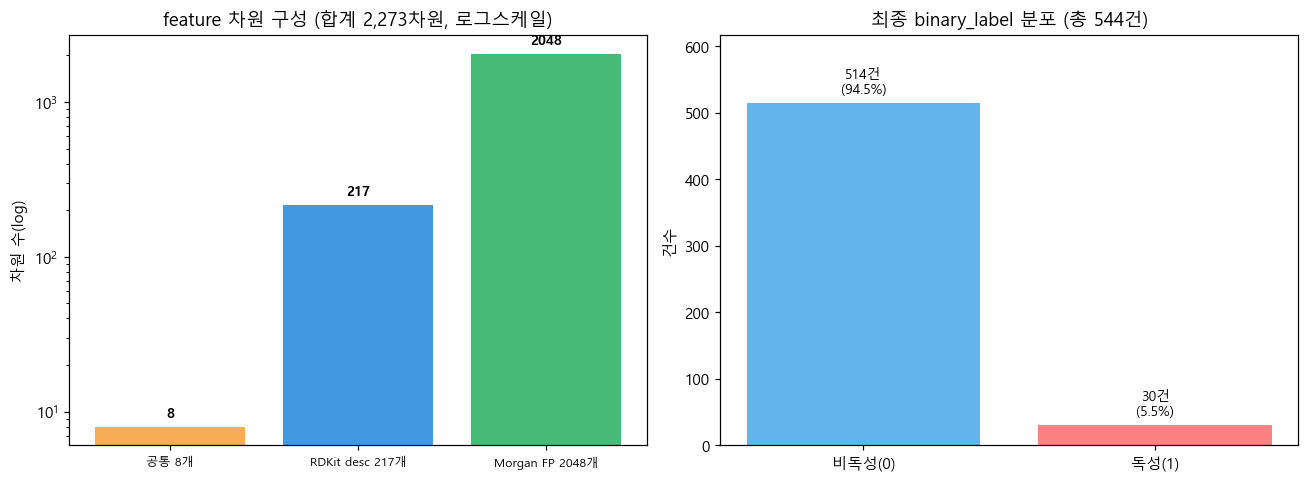

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

dims = [len(COMMON8_COLS), len(DESC217_COLS), len(FP_COLS)]
dim_labels = ["공통 8개", f"RDKit desc {len(DESC217_COLS)}개", f"Morgan FP {len(FP_COLS)}개"]
colors = ["#f6ad55", "#4299e1", "#48bb78"]
axes[0].bar(dim_labels, dims, color=colors)
axes[0].set_yscale("log")
for i, v in enumerate(dims):
    axes[0].text(i, v * 1.15, str(v), ha="center", fontsize=9, fontweight="bold")
axes[0].set_title(f"feature 차원 구성 (합계 {sum(dims):,}차원, 로그스케일)")
axes[0].set_ylabel("차원 수(log)")
axes[0].tick_params(axis="x", labelsize=8)

counts = final["binary_label"].value_counts().sort_index()
bars = axes[1].bar(["비독성(0)", "독성(1)"], [counts.get(0, 0), counts.get(1, 0)],
                    color=["#63b3ed", "#fc8181"])
axes[1].set_ylim(0, counts.max() * 1.2)
for b in bars:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2, h + counts.max() * 0.03,
                 f"{int(h)}건\n({h/counts.sum()*100:.1f}%)", ha="center", fontsize=9)
axes[1].set_title(f"최종 binary_label 분포 (총 {counts.sum()}건)")
axes[1].set_ylabel("건수")

plt.tight_layout()
plt.show()

## 한계점

1. **Morgan FP는 염 포함 원본 분자 기준**이라, 염 제거된 scalar descriptor(8개+217개)와 "같은 분자"를 보고 있지 않음 — eye팀 설계원칙을 그대로 따른 것이지만, 두 feature군이 서로 다른 분자 정의를 쓴다는 점은 모델링 시 염두에 둘 것.
2. **desc_ 217개 중 일부(BCUT2D_*, *PartialCharge 등)는 무기물 성분에서 원천적으로 NaN** — imputation 대신 결측 자체를 정보로 남겨둠(구체적 컬럼/건수는 3단계 출력 참고).
3. **feature 2,273차원 대비 샘플 544건(양성 30건)** — 샘플 대비 feature가 많아 과적합 위험이 여전히 큼(이전 세션에서 우려했던 지점). 모델링 시 정규화(dropout, L2) 또는 차원축소(PCA)를 강하게 권장.
4. 이 노트북은 skin만 대상으로 함 — eye도 동일 네이밍 규칙(desc_/fp_w_)으로 이미 구성돼 있어 향후 두 트랙 feature 스키마가 구조적으로 호환됨(완전 동일하진 않지만 같은 생성 로직).
5. **MIX839/MIX840(동일 조성)**: 2026-10-29에 worst-case 원칙으로 둘 다 Category 1(독성)로 라벨 통일. 이전에는 라벨을 각각 보존(1 vs 4)하고 comp_group_id만 공유했으나, "동일 입력에 상반된 정답을 요구하는" 학습 불가능한 모순이라는 판단에 따라 통일함.